# 📌 **Hands-on 4: Perceptrón Multicapa desde Cero (From Scratch)**
**Asignatura:** Deep Learning 2026B  
**Objetivo:** Implementar la arquitectura completa de un MLP en Python utilizando **únicamente NumPy** (sin librerías de Deep Learning), programando explícitamente el Forward Pass, Backpropagation y la actualización de pesos.

## **1. Fundamentos Matemáticos**
Para una red neuronal de 2 capas (Capa Oculta + Capa de Salida):

1. **Forward Pass:**
   - Capa Oculta: $Z_1 = X W_1 + b_1 \quad \rightarrow \quad A_1 = \sigma(Z_1)$
   - Capa de Salida: $Z_2 = A_1 W_2 + b_2 \quad \rightarrow \quad A_2 = \sigma(Z_2)$

2. **Función Sigmoide y Derivada:**
   - $\sigma(z) = \frac{1}{1 + e^{-z}}$
   - $\sigma'(z) = \sigma(z) \cdot (1 - \sigma(z))$

3. **Backpropagation:**
   - Error Salida: $\delta_2 = (A_2 - y) \odot \sigma'(Z_2)$
   - Gradiente Pesos 2: $\frac{\partial L}{\partial W_2} = A_1^T \delta_2$
   - Error Capa Oculta: $\delta_1 = (\delta_2 W_2^T) \odot \sigma'(Z_1)$
   - Gradiente Pesos 1: $\frac{\partial L}{\partial W_1} = X^T \delta_1$

In [1]:
# Importación de NumPy y herramientas básicas de evaluación/visualización
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix

print("Librerías listas.")

Librerías listas.


## **2. Carga y Preprocesamiento del Dataset**

El dataset Iris contiene 150 muestras de flores de tres especies diferentes. Para este ejercicio de clasificación binaria desde cero, utilizaremos dos características (Longitud y Ancho del Pétalo) para clasificar si una flor es de la especie Iris-Virginica o no.

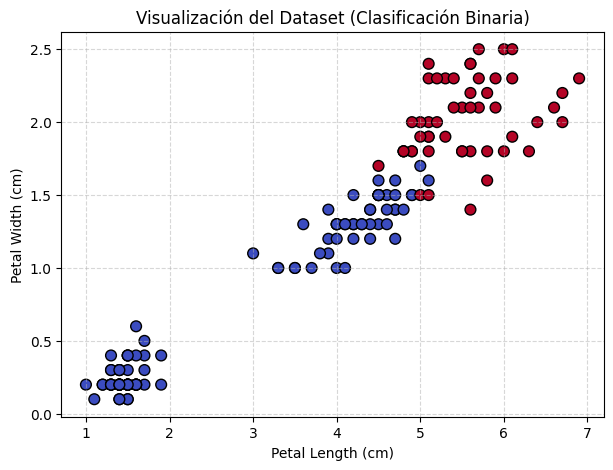

In [2]:
# Cargar dataset Iris
iris = load_iris()
# Seleccionar 2 características clave (Petal Length, Petal Width)
X = iris.data[:, (2, 3)]
# Clasificación binaria: 1 si es Iris-Virginica, 0 en otro caso
y = (iris.target == 2).astype(int).reshape(-1, 1)

# Visualización inicial
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap='coolwarm', edgecolors='k', s=60)
plt.title("Visualización del Dataset (Clasificación Binaria)")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# División y escalamiento
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## **3. Clase MLPFromScratch (Implementación NumPy)**

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_derivative(z):
    s = sigmoid(z)
    return s * (1 - s)

class MLPFromScratch:
    def __init__(self, input_size, hidden_size, output_size, learning_rate=0.05):
        self.lr = learning_rate
        # Inicialización gaussiana de pesos
        self.W1 = np.random.randn(input_size, hidden_size)
        self.W2 = np.random.randn(hidden_size, output_size)
        self.b1 = np.zeros((1, hidden_size))
        self.b2 = np.zeros((1, output_size))
        self.loss_history = []

    def fit(self, X, y, epochs=2000):
        for epoch in range(epochs):
            # --- FORWARD PASS ---
            Z1 = np.dot(X, self.W1) + self.b1
            A1 = sigmoid(Z1)
            Z2 = np.dot(A1, self.W2) + self.b2
            A2 = sigmoid(Z2)

            # Pérdida MSE para seguimiento
            loss = np.mean((A2 - y) ** 2)
            self.loss_history.append(loss)

            # --- BACKPROPAGATION ---
            error_output = A2 - y
            dZ2 = error_output * sigmoid_derivative(Z2)
            dW2 = np.dot(A1.T, dZ2)
            db2 = np.sum(dZ2, axis=0, keepdims=True)

            error_hidden = np.dot(dZ2, self.W2.T)
            dZ1 = error_hidden * sigmoid_derivative(Z1)
            dW1 = np.dot(X.T, dZ1)
            db1 = np.sum(dZ1, axis=0, keepdims=True)

            # --- ACTUALIZACIÓN DE PARÁMETROS ---
            self.W2 -= self.lr * dW2
            self.b2 -= self.lr * db2
            self.W1 -= self.lr * dW1
            self.b1 -= self.lr * db1

    def predict(self, X):
        Z1 = np.dot(X, self.W1) + self.b1
        A1 = sigmoid(Z1)
        Z2 = np.dot(A1, self.W2) + self.b2
        A2 = sigmoid(Z2)
        return (A2 >= 0.5).astype(int)

print("Clase MLPFromScratch definida correctamente.")

Clase MLPFromScratch definida correctamente.


## **4. Entrenamiento y Gráfica de Convergencia**

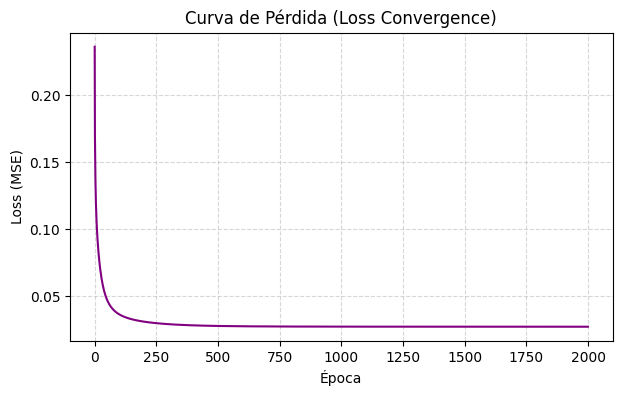

In [4]:
# Instanciar y entrenar
model = MLPFromScratch(input_size=2, hidden_size=4, output_size=1, learning_rate=0.05)
model.fit(X_train_scaled, y_train, epochs=2000)

# Gráfica de la curva de pérdida
plt.figure(figsize=(7, 4))
plt.plot(model.loss_history, color='purple')
plt.title("Curva de Pérdida (Loss Convergence)")
plt.xlabel("Época")
plt.ylabel("Loss (MSE)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## **5. Evaluación de Resultados**

🎯 Exactitud (Accuracy): 100.00%


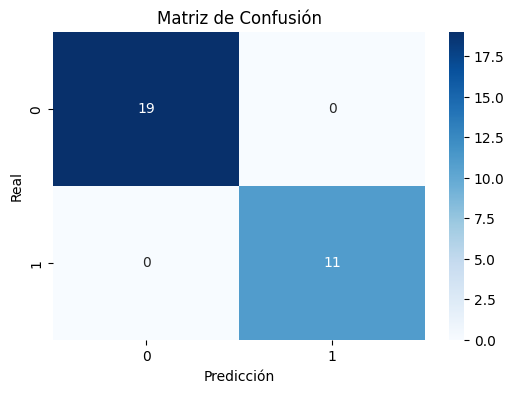

In [5]:
import seaborn as sns

y_pred = model.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"🎯 Exactitud (Accuracy): {acc * 100:.2f}%")

# Agregar la gráfica de la matriz de confusión
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Matriz de Confusión")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.show()